# Alquiler — 04 Modelo OLS

Modelo de regresión lineal con **`statsmodels` OLS** para predecir el precio de
alquiler de Moscú en log (`log_rent`), sobre la matriz `FEATURES_BASE` (p = 38)
definida en la etapa de feature engineering.

**Principio de trabajo (vale para todo el notebook):** cada acción se toma con
comparación, tradeoff y criterio declarado *antes* de ver el resultado. Nada se
adopta por convención: agrupar o no las dummies, el tamaño del modelo y el
modelo final salen de competencias con regla previa.

**Datos de entrada y reglas:**

- Entrada: `rentals_train_fe.csv` y `rentals_test_fe.csv` de `data/processed/`.
  Split 80/20: 16.000 filas de train y 4.000 de test.
- Toda selección se hace **solo con train**. Test se evalúa **una sola vez**,
  sobre el modelo final ya elegido, y nunca para elegir.
- El target del ajuste es `log_rent`; el error comunicable final es en
  RUB/mes (`monthly_rent_rub`), con predicciones convertidas por `expm1(...)`.

**Recorrido:** (1) baseline con las 38 y su batería completa de análisis en 7
pasos; (2) competencia agrupado vs. libre y Forward Stepwise en ambas variantes;
(3) Best Subset Selection sobre el universo factible de la variante ganadora;
(4) elección del modelo final por la regla de 1 SE (el punto donde más
complejidad ya no baja el error de predicción de forma apreciable) y su única
evaluación en test; (5) registro y verificación de los 8 modelos en MLflow
(DagsHub remoto, experimento **`Alquiler`**).


## 0. Entorno y datos de entrada

Correr con el kernel **`.venv`** del proyecto. La celda siguiente localiza la
raíz (donde están `.env` y `data/`), verifica el intérprete y carga las matrices
ya preparadas de train y test. `FEATURES_BASE` tiene 38 predictores y **no incluye `id`**
(va con assert): son 3 continuas estandarizadas + 3 numéricas/binarias + 32
dummies de 5 categóricas (`rooms`, `building_type`, `renovation`, `okrug`,
`metro_line`).

In [1]:
from pathlib import Path
import sys

RAIZ = next((b for b in [Path.cwd(), *Path.cwd().parents]
             if (b / ".env").is_file() and (b / "data").is_dir()), None)
assert RAIZ is not None, "No se encontró la raíz del proyecto (.env + data/)."
assert Path(sys.prefix).resolve() == (RAIZ / ".venv").resolve(), (
    "Seleccionar el kernel .venv del proyecto antes de continuar.")
print(f"raíz: {RAIZ} | intérprete: {sys.executable}")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from statsmodels.stats.diagnostic import het_breuschpagan  # noqa: F401 (disponible para contraste)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest

DATA_DIR = RAIZ / "data"
OUT_DIR = DATA_DIR / "processed"
Y = "log_rent"
TARGET = "monthly_rent_rub"
SEED = 42

FEATURES_BASE = [
    "log_area_z", "log_center_z", "log_metro_z", "deposit_months",
    "furnished", "pets_allowed", "rooms_2", "rooms_3", "rooms_4",
    "building_type_brick", "building_type_khrushchev",
    "building_type_modern_panel", "building_type_monolith",
    "building_type_stalin", "renovation_designer", "renovation_euro",
    "renovation_no_renovation", "okrug_CAO", "okrug_NAO", "okrug_SAO",
    "okrug_SZAO", "okrug_TAO", "okrug_VAO", "okrug_YuAO", "okrug_YuZAO",
    "okrug_ZAO", "okrug_ZelAO", "metro_line_Arbatsko-Pokrovskaya",
    "metro_line_Bolshaya Koltsevaya", "metro_line_Filyovskaya",
    "metro_line_Kalininskaya", "metro_line_Koltsevaya",
    "metro_line_Lyublinsko-Dmitrovskaya", "metro_line_MCC",
    "metro_line_Serpukhovsko-Timiryazevskaya", "metro_line_Sokolnicheskaya",
    "metro_line_Tagansko-Krasnopresnenskaya", "metro_line_Zamoskvoretskaya",
]
assert len(FEATURES_BASE) == 38 and "id" not in FEATURES_BASE

train = pd.read_csv(OUT_DIR / "rentals_train_fe.csv")
test = pd.read_csv(OUT_DIR / "rentals_test_fe.csv")
assert train.shape[0] == 16000 and test.shape[0] == 4000
assert all(c in train.columns for c in FEATURES_BASE + [Y, TARGET])
assert train[FEATURES_BASE].isna().sum().sum() == 0
print(f"train {len(train):,} | test {len(test):,} (reservado) | p = {len(FEATURES_BASE)} | target {Y}")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Folds de CV únicos para todas las competencias (comparabilidad y honestidad)
FOLDS = list(KFold(5, shuffle=True, random_state=SEED).split(train))


def fit_ols(cols, datos=train):
    X = sm.add_constant(datos[list(cols)].astype(float), has_constant="add")
    return sm.OLS(datos[Y].astype(float), X).fit()


def cv_rmse(cols):
    # (doc)
    if len(cols) == 0:
        rms = [np.sqrt(mean_squared_error(
            train[Y].iloc[vai],
            np.full(len(vai), train[Y].iloc[tri].mean())))
            for tri, vai in FOLDS]
    else:
        Xa = train[list(cols)].astype(float).to_numpy()
        yv = train[Y].astype(float).to_numpy()
        rms = []
        for tri, vai in FOLDS:
            m = LinearRegression().fit(Xa[tri], yv[tri])
            rms.append(np.sqrt(mean_squared_error(yv[vai], m.predict(Xa[vai]))))
    return float(np.mean(rms)), float(np.std(rms, ddof=1) / np.sqrt(len(rms)))


def metricas_log(modelo, cols):
    # (doc)
    pred = modelo.fittedvalues
    rss = float(modelo.ssr)
    cv, se = cv_rmse(cols)
    return {
        "n_columnas": len(cols), "R2": float(modelo.rsquared),
        "Adj_R2": float(modelo.rsquared_adj), "AIC": float(modelo.aic),
        "BIC": float(modelo.bic), "RSS_log": rss,
        "MSE_log": rss / int(modelo.nobs), "MAE_log": float(mean_absolute_error(train[Y], pred)),
        "CV_RMSE_log": cv, "CV_SE": se,
    }


raíz: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals | intérprete: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/.venv/bin/python3.14


train 16,000 | test 4,000 (reservado) | p = 38 | target log_rent


## 1. Baseline: modelo completo con las 38 (solo train)

Punto de partida y punto de comparación de todo lo que sigue: ajustar **todo** y
leer el resultado entero antes de descartar nada. Este modelo no es el final: es
la evidencia contra la que compiten las selecciones.

La batería de análisis corre en un orden que sigue las preguntas del lector (y
las 3 partes del `summary()`):

1. **Ajuste global** — ¿el modelo en conjunto explica algo? (R², Adj R², F, AIC/BIC)
2. **Colinealidad** — VIF y Tolerancia: ¿se pueden creer los coeficientes?
3. **Coeficientes** — coef, std err, t, P>|t|, IC 95% (corte p ≤ 0,05).
4. **Sesgo y homocedasticidad** — residuos vs. ajustados y Scale-Location.
5. **Normalidad** — histograma y QQ-plot (manda lo visual), con Omnibus, Skew,
   Kurtosis y Jarque-Bera de respaldo.
6. **Independencia e influyentes** — Durbin-Watson y Residuals vs. Leverage.
7. **Costo** — RSS, MSE (= RSS/n) y MAE en log (escala del ajuste).

In [2]:
baseline = fit_ols(FEATURES_BASE)
print(baseline.summary().as_text())


                            OLS Regression Results                            
Dep. Variable:               log_rent   R-squared:                       0.926
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     5231.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:54:55   Log-Likelihood:                 7856.7
No. Observations:               16000   AIC:                        -1.564e+04
Df Residuals:                   15961   BIC:                        -1.534e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

In [3]:
def tabla_coeficientes(modelo):
    ci = modelo.conf_int()
    return pd.DataFrame({
        "coef": modelo.params, "std_err": modelo.bse, "t": modelo.tvalues,
        "p_valor": modelo.pvalues, "IC95_inf": ci[0], "IC95_sup": ci[1],
        "significativo_005": modelo.pvalues < 0.05,
    })


def tabla_vif(cols):
    X = sm.add_constant(train[list(cols)].astype(float), has_constant="add")
    vif = pd.Series(
        [variance_inflation_factor(X.to_numpy(), i) for i in range(X.shape[1])],
        index=X.columns).drop("const")
    return pd.DataFrame({"VIF": vif, "Tol": 1.0 / vif}).sort_values("VIF", ascending=False)


def bateria_tablas(modelo, cols, titulo):
    # (doc)
    met = metricas_log(modelo, cols)
    om, om_p = omni_normtest(modelo.resid)
    jb, jb_p, skew, kurt = jarque_bera(modelo.resid)
    print(f"===== {titulo} =====")
    print("— Paso 1 · Ajuste global —")
    print(pd.Series({
        "R2": met["R2"], "Adj_R2": met["Adj_R2"],
        "F_statistic": float(modelo.fvalue), "Prob(F)": float(modelo.f_pvalue),
        "Log-Likelihood": float(modelo.llf), "AIC": met["AIC"], "BIC": met["BIC"],
        "n": int(modelo.nobs), "Df_modelo": int(modelo.df_model),
        "Df_residuos": int(modelo.df_resid), "Cond_No": float(np.linalg.cond(modelo.model.exog)),
    }).round(4).to_string())
    print("\n— Paso 2 · Colinealidad (VIF alto ⇒ coef. poco creíble; Tol = 1/VIF) —")
    vif = tabla_vif(cols)
    display(vif.round(3))
    print(f"VIF máximo: {vif['VIF'].max():.2f} (umbral de alerta habitual: 5; severo: 10)")
    print("\n— Paso 3 · Coeficientes (t ≠ 0 y p ≤ 0,05) —")
    coef = tabla_coeficientes(modelo)
    display(coef.round(4))
    print(f"no significativos (p > 0,05): {list(coef.index[~coef['significativo_005']])}")
    print("\n— Paso 5 · Normalidad (respaldo numérico; manda la lectura visual) —")
    print(pd.Series({"Omnibus": om, "Prob(Omnibus)": om_p, "Skew": skew,
                     "Kurtosis": kurt, "Jarque-Bera": jb, "Prob(JB)": jb_p}).round(4).to_string())
    print("\n— Paso 6 · Independencia —")
    print(f"Durbin-Watson: {durbin_watson(modelo.resid):.3f}  (≈2 sin autocorr.; "
          "en corte transversal depende del orden de filas: se reporta con cautela)")
    print("\n— Paso 7 · Costo en log (escala del ajuste, train) —")
    print(pd.Series({"RSS": met["RSS_log"], "MSE (=RSS/n)": met["MSE_log"],
                     "MAE": met["MAE_log"]}).round(5).to_string())
    return {"metricas": met, "vif": vif, "coeficientes": coef}


def graficos_diagnostico(modelo, titulo):
    # (doc)
    resid, fitted = np.asarray(modelo.resid), np.asarray(modelo.fittedvalues)
    infl = modelo.get_influence()
    lev = infl.hat_matrix_diag
    r_int = infl.resid_studentized_internal
    n_obs, n_par = int(modelo.nobs), int(modelo.df_model) + 1
    # Studentizado externo por forma cerrada: el de statsmodels usa determinantes
    # leave-one-out que desbordan en float y emiten RuntimeWarning (det).
    stud = r_int * np.sqrt((n_obs - n_par - 1) / (n_obs - n_par - r_int**2))
    cook = infl.cooks_distance[0]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(fitted, resid, s=5, alpha=0.25)
    axes[0].axhline(0, color="red", lw=1.2)
    axes[0].set_xlabel("Valores ajustados"); axes[0].set_ylabel("Residuos")
    axes[0].set_title("Residuos vs. ajustados")
    axes[1].scatter(fitted, np.sqrt(np.abs(infl.resid_studentized_internal)), s=5, alpha=0.25)
    axes[1].set_xlabel("Valores ajustados"); axes[1].set_ylabel("√|residuos estandarizados|")
    axes[1].set_title("Scale-Location")
    fig.suptitle(f"{titulo} — sesgo y homocedasticidad", fontsize=12)
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(resid, bins=60, edgecolor="white", lw=0.3)
    axes[0].axvline(0, color="red", lw=1.2)
    axes[0].set_xlabel("Residuo"); axes[0].set_ylabel("Frecuencia")
    axes[0].set_title("Histograma de residuos")
    sm.qqplot(resid, line="45", fit=True, ax=axes[1])
    axes[1].set_title("QQ-plot")
    fig.suptitle(f"{titulo} — normalidad", fontsize=12)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(lev, stud, s=5, alpha=0.25)
    ax.axhline(0, color="red", lw=1)
    ax.set_xlabel("Leverage"); ax.set_ylabel("Residuos estudentizados")
    ax.set_title(f"{titulo} — Residuals vs. Leverage")
    plt.tight_layout(); plt.show()
    print(f"Distancia de Cook máxima: {cook.max():.4f} "
          f"(muy por debajo de 1: ningún punto domina el ajuste)")
    return {"leverage": lev, "cook": cook, "studentized": stud}


===== Baseline (38 variables) =====
— Paso 1 · Ajuste global —
R2                    0.9257
Adj_R2                0.9255
F_statistic        5231.4137
Prob(F)               0.0000
Log-Likelihood     7856.6534
AIC              -15635.3067
BIC              -15335.7733
n                 16000.0000
Df_modelo            38.0000
Df_residuos       15961.0000
Cond_No              25.2654

— Paso 2 · Colinealidad (VIF alto ⇒ coef. poco creíble; Tol = 1/VIF) —


,VIF,Tol
log_center_z,4.433,0.226
log_area_z,3.845,0.260
rooms_3,3.167,0.316
okrug_TAO,2.886,0.346
rooms_4,2.378,0.421
okrug_CAO,2.314,0.432
rooms_2,2.288,0.437
okrug_NAO,1.942,0.515
okrug_VAO,1.927,0.519
log_metro_z,1.922,0.520


VIF máximo: 4.43 (umbral de alerta habitual: 5; severo: 10)

— Paso 3 · Coeficientes (t ≠ 0 y p ≤ 0,05) —


,coef,std_err,t,p_valor,IC95_inf,IC95_sup,significativo_005
const,10.4601,0.0062,1693.4451,0.0000,10.4480,10.4722,True
log_area_z,0.2284,0.0023,99.3816,0.0000,0.2239,0.2329,True
log_center_z,-0.1480,0.0025,-59.9658,0.0000,-0.1528,-0.1432,True
log_metro_z,-0.1555,0.0016,-95.6655,0.0000,-0.1587,-0.1523,True
deposit_months,0.0013,0.0022,0.6168,0.5374,-0.0029,0.0056,False
furnished,0.0790,0.0026,30.8732,0.0000,0.0740,0.0840,True
pets_allowed,-0.0266,0.0026,-10.4405,0.0000,-0.0316,-0.0216,True
rooms_2,-0.0009,0.0037,-0.2338,0.8152,-0.0082,0.0064,False
rooms_3,-0.0035,0.0058,-0.6044,0.5456,-0.0150,0.0079,False
rooms_4,-0.0026,0.0085,-0.3065,0.7593,-0.0193,0.0141,False


no significativos (p > 0,05): ['deposit_months', 'rooms_2', 'rooms_3', 'rooms_4', 'metro_line_Bolshaya Koltsevaya', 'metro_line_Kalininskaya', 'metro_line_Lyublinsko-Dmitrovskaya', 'metro_line_MCC', 'metro_line_Serpukhovsko-Timiryazevskaya']

— Paso 5 · Normalidad (respaldo numérico; manda la lectura visual) —
Omnibus          20.0658
Prob(Omnibus)     0.0000
Skew             -0.0730
Kurtosis          2.9095
Jarque-Bera      19.6895
Prob(JB)          0.0001

— Paso 6 · Independencia —
Durbin-Watson: 1.989  (≈2 sin autocorr.; en corte transversal depende del orden de filas: se reporta con cautela)

— Paso 7 · Costo en log (escala del ajuste, train) —
RSS             350.85929
MSE (=RSS/n)      0.02193
MAE               0.11872


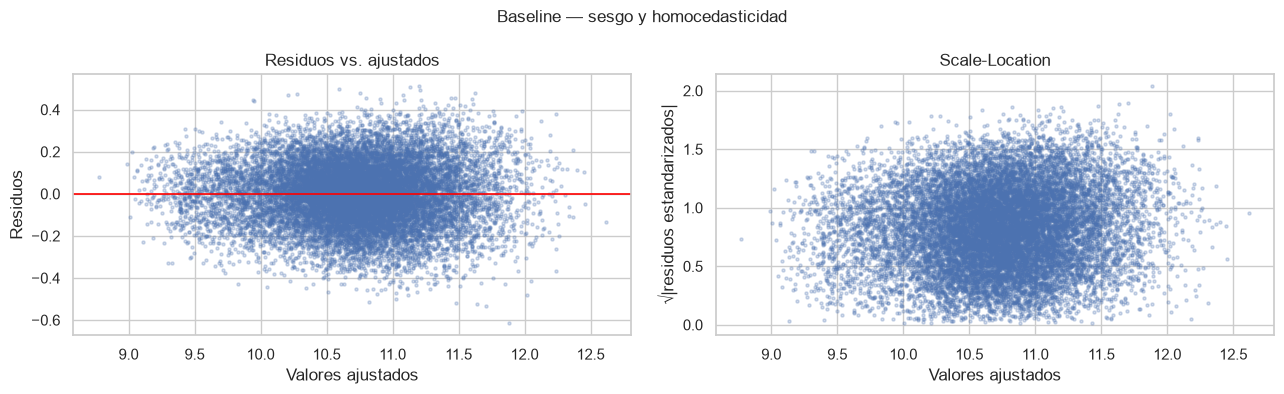

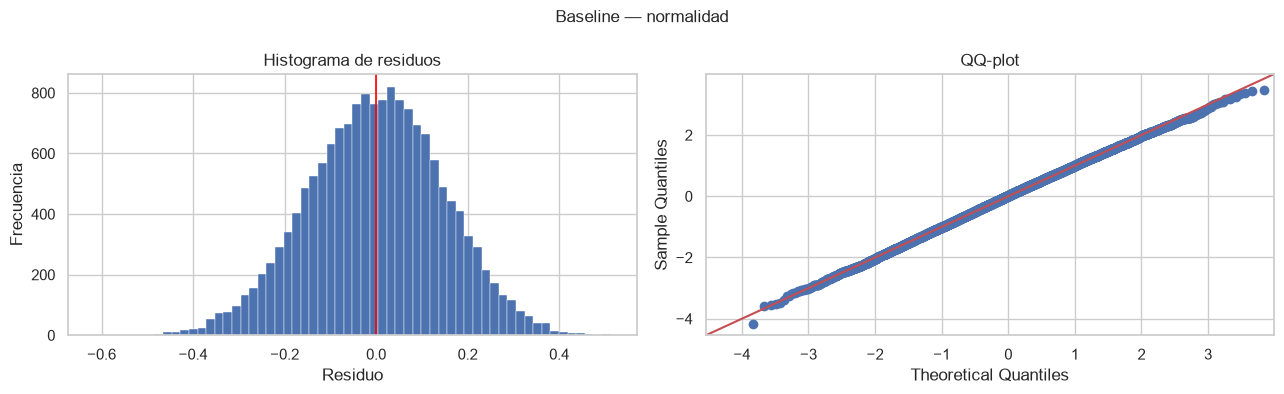

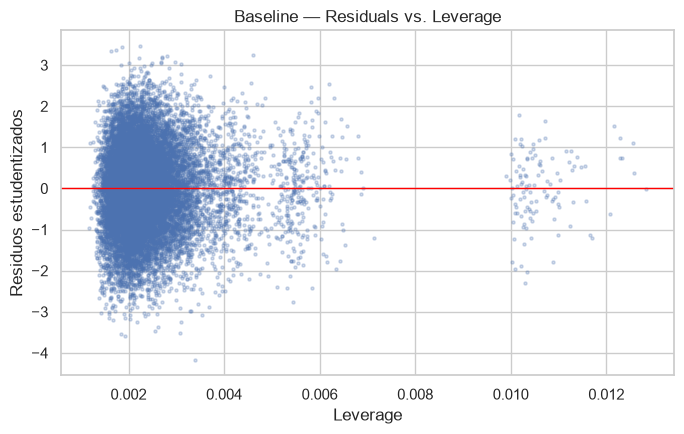

Distancia de Cook máxima: 0.0015 (muy por debajo de 1: ningún punto domina el ajuste)


In [4]:
res_base = bateria_tablas(baseline, FEATURES_BASE, "Baseline (38 variables)")
graf_base = graficos_diagnostico(baseline, "Baseline")


**Lectura del baseline (sobre lo impreso y graficado arriba).**

*Ajuste global:* R² = 0,926 y Adj R² = 0,926 (prácticamente iguales: con 38
parámetros sobre 16.000 casos el castigo es mínimo), F = 5.231 con Prob(F) ≈ 0:
el modelo en conjunto explica, y mucho. AIC = −15.635 y BIC = −15.336 son el
piso que toda selección posterior tiene que mejorar o justificar.

*Colinealidad:* VIF máximo = 4,43 (`log_center_z`, Tol = 0,23) seguido por
`log_area_z` (3,84) y `rooms_3` (3,17): todo por debajo del umbral de alerta de
5. Los coeficientes se pueden interpretar de a uno; la cercanía
centro–metro–superficie infla algo los errores estándar, pero no inhabilita.

*Coeficientes:* 30 de 39 filas (38 + intercepto) son significativas. Las que no
superan p ≤ 0,05 son las mismas que después desaparecen de todas las
selecciones: `deposit_months`, las tres dummies de `rooms` (con la superficie en
el modelo, la cantidad de ambientes no aporta) y cinco líneas de metro
(`Bolshaya Koltsevaya`, `Kalininskaya`, `Lyublinsko-Dmitrovskaya`, `MCC`,
`Serpukhovsko-Timiryazevskaya`). Los signos son los esperados: superficie y
renovación designer al alza; distancia al centro y al metro a la baja; CAO el
okrug más caro y TAO el más barato.

*Residuos:* la nube contra ajustados está centrada en 0 sin curva visible (sin
sesgo sistemático) y con dispersión aproximadamente constante; el Scale-Location
lo confirma con una banda sin tendencia fuerte, así que la lectura es
**homocedasticidad razonable** para predecir (los contrastes formales con
n = 16.000 detectan desvíos sin relevancia práctica). El histograma es campana
simétrica (Skew = −0,07, Kurtosis = 2,91) y el QQ-plot sigue la recta salvo
colas levemente cortas: Omnibus y Jarque-Bera rechazan (p ≈ 10⁻⁴–10⁻⁵), pero
con esta n rechazan por desvíos mínimos; manda la lectura visual, que es de
normalidad aceptable. Durbin-Watson = 1,99, sin señal de autocorrelación (con la
cautela del orden de filas). La distancia de Cook máxima es 0,0016, muy por
debajo de 1: ningún punto domina el ajuste.

*Costo (log, train):* RSS = 350,86, MSE = 0,0219, MAE = 0,1187. Es el piso a
batir en simplicidad, no necesariamente en error: las selecciones compiten por
lograr lo mismo con menos columnas.


## 2. ¿Agrupar las dummies? Competencia previa y Forward Stepwise

Una posibilidad es que cada categórica (p. ej. `okrug` con sus 10 dummies)
entre o salga **como un bloque**. 

- **Variante agrupada (11 características):** las 6 individuales
  (`log_area_z`, `log_center_z`, `log_metro_z`, `deposit_months`, `furnished`,
  `pets_allowed`) más los bloques `rooms` (3), `building_type` (5),
  `renovation` (3), `okrug` (10) y `metro_line` (11).
- **Variante libre (38 características):** cada columna suelta.

*Tradeoff:* agrupar conserva la categoría íntegra e interpretable y toma solo
11 decisiones de selección (menos varianza de selección), pero puede arrastrar
dummies débiles dentro de un bloque fuerte; la libre puede podar categoría por
categoría (menos sesgo potencial), pero con 38 decisiones corre más riesgo de
elegir categorías por ruido y deja categorías fragmentadas.

**Regla declarada antes de correr (vale para esta competencia):** corre el
mismo Forward Stepwise en ambas variantes (tres criterios independientes:
AIC y BIC con mejora mínima 2,0; R² ajustado con mejora mínima 0,0001; sin
tope artificial, desde el modelo solo-intercepto, todo en train). Se adopta
la variante **agrupada** salvo que la libre la supere en CV 5-fold (mismos
folds, RMSE en log) por **más de 1 error estándar** *y* en BIC con
**ΔBIC > 10**, comparando el mejor modelo por CV de cada variante. Como
evidencia de apoyo se muestra cuántas dummies de cada bloque elige la libre.
Test no interviene.

In [5]:
GRUPOS = {
    "log_area_z": ["log_area_z"], "log_center_z": ["log_center_z"],
    "log_metro_z": ["log_metro_z"], "deposit_months": ["deposit_months"],
    "furnished": ["furnished"], "pets_allowed": ["pets_allowed"],
    "rooms": [c for c in FEATURES_BASE if c.startswith("rooms_")],
    "building_type": [c for c in FEATURES_BASE if c.startswith("building_type_")],
    "renovation": [c for c in FEATURES_BASE if c.startswith("renovation_")],
    "okrug": [c for c in FEATURES_BASE if c.startswith("okrug_")],
    "metro_line": [c for c in FEATURES_BASE if c.startswith("metro_line_")],
}
LIBRE = {c: [c] for c in FEATURES_BASE}
assert sum(len(v) for v in GRUPOS.values()) == 38 and len(GRUPOS) == 11
print(pd.DataFrame([{"caracteristica": k, "n_columnas": len(v),
                     "columnas": ", ".join(v)} for k, v in GRUPOS.items()]
                   ).to_string(index=False))

CONFIG_STEPWISE = {
    "AIC": {"criterio": "aic", "mejora_minima": 2.0},
    "BIC": {"criterio": "bic", "mejora_minima": 2.0},
    "AdjR2": {"criterio": "adj_r2", "mejora_minima": 0.0001},
}
_cache_stepwise = {}


def _stats_cols(cols):
    clave = tuple(cols)
    if clave not in _cache_stepwise:
        f = fit_ols(list(cols)) if cols else sm.OLS(
            train[Y].astype(float),
            pd.DataFrame({"const": 1.0}, index=train.index)).fit()
        _cache_stepwise[clave] = (float(f.aic), float(f.bic), float(f.rsquared_adj))
    return _cache_stepwise[clave]


def forward_stepwise(grupos, criterio, mejora_minima):
    idx = {"aic": 0, "bic": 1, "adj_r2": 2}[criterio]
    sel, cols = [], []
    actual = _stats_cols([])[idx]
    historial = [{"paso": 0, "caracteristica": "intercepto", "valor": actual,
                  "mejora": 0.0, "n_caracteristicas": 0, "n_columnas": 0}]
    while len(sel) < len(grupos):
        mejor = None
        for nombre, gcols in grupos.items():
            if nombre in sel:
                continue
            cand = [c for c in FEATURES_BASE if c in set(cols) | set(gcols)]
            valor = _stats_cols(cand)[idx]
            mejora = valor - actual if criterio == "adj_r2" else actual - valor
            if mejor is None or mejora > mejor["mejora"]:
                mejor = {"nombre": nombre, "valor": valor, "mejora": mejora, "columnas": cand}
        if mejor is None or mejor["mejora"] < mejora_minima:
            break
        sel.append(mejor["nombre"]); cols = mejor["columnas"]; actual = mejor["valor"]
        historial.append({"paso": len(sel), "caracteristica": mejor["nombre"],
                          "valor": actual, "mejora": mejor["mejora"],
                          "n_caracteristicas": len(sel), "n_columnas": len(cols)})
    return {"seleccionadas": sel, "columnas": cols, "historial": pd.DataFrame(historial)}


caracteristica  n_columnas                                                                                                                                                                                                                                                                                                                              columnas
    log_area_z           1                                                                                                                                                                                                                                                                                                                            log_area_z
  log_center_z           1                                                                                                                                                                                                                                                                            

In [6]:
selecciones = {}
for variante, grupos in [("agrupado", GRUPOS), ("libre", LIBRE)]:
    for nombre, cfg in CONFIG_STEPWISE.items():
        s = forward_stepwise(grupos, cfg["criterio"], cfg["mejora_minima"])
        selecciones[(variante, nombre)] = s
        print(f"\n### {variante} · {nombre} — {len(s['seleccionadas'])} características, "
              f"{len(s['columnas'])} columnas")
        print(s["historial"].round(5).to_string(index=False))
        print("conjunto:", s["seleccionadas"])



### agrupado · AIC — 9 características, 34 columnas
 paso caracteristica        valor      mejora  n_caracteristicas  n_columnas
    0     intercepto  25878.26610     0.00000                  0           0
    1          okrug  12321.52892 13556.73718                  1          10
    2     log_area_z   3666.65076  8654.87816                  2          11
    3    log_metro_z  -2026.63814  5693.28890                  3          12
    4     renovation  -6775.55882  4748.92068                  4          15
    5  building_type -11307.06188  4531.50307                  5          20
    6   log_center_z -14501.48865  3194.42676                  6          21
    7      furnished -15414.21889   912.73024                  7          22
    8     metro_line -15535.55200   121.33311                  8          33
    9   pets_allowed -15642.48200   106.93000                  9          34
conjunto: ['okrug', 'log_area_z', 'log_metro_z', 'renovation', 'building_type', 'log_center_z', 'fur


### libre · AIC — 30 características, 30 columnas
 paso                         caracteristica        valor      mejora  n_caracteristicas  n_columnas
    0                             intercepto  25878.26610     0.00000                  0           0
    1                           log_center_z  14546.86970 11331.39640                  1           1
    2                             log_area_z   7248.69873  7298.17097                  2           2
    3                            log_metro_z   3651.73314  3596.96558                  3           3
    4                    renovation_designer   2123.63790  1528.09524                  4           4
    5                              okrug_ZAO    687.98684  1435.65107                  5           5
    6                        renovation_euro   -896.31966  1584.30650                  6           6
    7                             okrug_SZAO  -2653.50827  1757.18861                  7           7
    8                            okrug_Y

In [7]:
# Modelos stepwise ajustados y comparación de la competencia (solo train)
modelos_stepwise = {}
filas_comp = []
for (variante, nombre), s in selecciones.items():
    m = fit_ols(s["columnas"])
    modelos_stepwise[(variante, nombre)] = m
    met = metricas_log(m, s["columnas"])
    filas_comp.append({"modelo": f"{variante}_{nombre}", "variante": variante,
                       "criterio": nombre, "n_caracteristicas": len(s["seleccionadas"]),
                       **met})
comp_stepwise = pd.DataFrame(filas_comp)
display(comp_stepwise[["modelo", "n_caracteristicas", "n_columnas", "R2", "Adj_R2",
                       "AIC", "BIC", "MAE_log", "CV_RMSE_log", "CV_SE"]].round(5))

# Evidencia de apoyo: cuántas dummies de cada bloque elige la libre
apoyo = {}
for nombre in CONFIG_STEPWISE:
    cols_libre = set(selecciones[("libre", nombre)]["columnas"])
    apoyo[nombre] = {g: f"{sum(c in cols_libre for c in gc)}/{len(gc)}"
                     for g, gc in GRUPOS.items() if len(gc) > 1}
print("\nDummies elegidas por la variante libre, por bloque (elegidas/total):")
display(pd.DataFrame(apoyo))

# Aplicación de la regla declarada (representante = mejor CV de cada variante)
rep = {}
for variante in ["agrupado", "libre"]:
    sub = comp_stepwise[comp_stepwise["variante"] == variante]
    rep[variante] = sub.loc[sub["CV_RMSE_log"].idxmin()]
d_cv = float(rep["agrupado"]["CV_RMSE_log"] - rep["libre"]["CV_RMSE_log"])
d_bic = float(rep["agrupado"]["BIC"] - rep["libre"]["BIC"])
gana_libre = (d_cv < -float(rep["agrupado"]["CV_SE"])) and (d_bic > 10)
VARIANTE_GANADORA = "libre" if gana_libre else "agrupado"
print(f"\nRepresentante agrupado: {rep['agrupado']['modelo']} "
      f"(CV={rep['agrupado']['CV_RMSE_log']:.5f}, BIC={rep['agrupado']['BIC']:.1f})")
print(f"Representante libre:    {rep['libre']['modelo']} "
      f"(CV={rep['libre']['CV_RMSE_log']:.5f}, BIC={rep['libre']['BIC']:.1f})")
print(f"ΔCV (agrupado − libre) = {d_cv:+.5f} | 1 SE agrupado = {rep['agrupado']['CV_SE']:.5f} | "
      f"ΔBIC (agrupado − libre) = {d_bic:+.1f}")
print(f"¿Libre supera en CV por >1 SE y en BIC por >10? {gana_libre}")
print(f"==> VARIANTE GANADORA: {VARIANTE_GANADORA}")


,modelo,n_caracteristicas,n_columnas,R2,Adj_R2,AIC,BIC,MAE_log,CV_RMSE_log,CV_SE
0,agrupado_AIC,9,34,0.92567,0.92552,-15642.48200,-15373.66996,0.11874,0.14846,0.00057
1,agrupado_BIC,9,34,0.92567,0.92552,-15642.48200,-15373.66996,0.11874,0.14846,0.00057
2,agrupado_AdjR2,9,34,0.92567,0.92552,-15642.48200,-15373.66996,0.11874,0.14846,0.00057
3,libre_AIC,30,30,0.92564,0.92550,-15643.62493,-15405.53426,0.11877,0.14848,0.00057
4,libre_BIC,27,27,0.92555,0.92543,-15630.81802,-15415.76839,0.11884,0.14854,0.00056
5,libre_AdjR2,26,26,0.92548,0.92536,-15616.24102,-15408.87173,0.11891,0.14860,0.00055



Dummies elegidas por la variante libre, por bloque (elegidas/total):


,AIC,BIC,AdjR2
rooms,0/3,0/3,0/3
building_type,5/5,5/5,5/5
renovation,3/3,3/3,3/3
okrug,10/10,10/10,9/10
metro_line,7/11,4/11,4/11



Representante agrupado: agrupado_AIC (CV=0.14846, BIC=-15373.7)
Representante libre:    libre_AIC (CV=0.14848, BIC=-15405.5)
ΔCV (agrupado − libre) = -0.00001 | 1 SE agrupado = 0.00057 | ΔBIC (agrupado − libre) = +31.9
¿Libre supera en CV por >1 SE y en BIC por >10? False
==> VARIANTE GANADORA: agrupado


**Lectura de la competencia.** Las tres corridas agrupadas convergen al mismo
modelo: 9 características y 34 columnas (todo menos `deposit_months` y el bloque
`rooms`, que confirman en bloque lo que el baseline sugería por p-valores). La
libre llega a modelos de 26–30 columnas: elige enteros los bloques
`building_type` (5/5), `renovation` (3/3) y `okrug` (10/10 o 9/10 según criterio)
y poda `metro_line` (4–7 de 11), sin tocar `rooms` (0/3) — es decir, el trabajo
de poda real de la libre se concentra en un solo bloque.

En la regla: el representante libre tiene mejor BIC (ΔBIC = +32 a su favor, por
sus menos columnas con RSS casi igual), **pero no supera en CV** (ΔCV ≈ 0,0000,
muy lejos del 1 SE = 0,0006 exigido). Como la regla pide ambas condiciones, la
ganadora es la **agrupada**: ante empate predictivo práctico se prefiere la
variante con 11 decisiones de selección y categorías íntegras, que es la que
menor varianza de selección introduce. El BIC de la libre queda registrado como
el costo de esa elección (se aceptan 34 columnas donde 30 predecían igual),
deliberado y documentado, no escondido.

## 3. Best Subset Selection: ¿el greedy dejó algo mejor en el camino?

El stepwise es voraz: elige lo mejor en cada paso sin mirar combinaciones, así
que su conjunto puede no ser el mejor de su tamaño. Best Subset revisa **todos**
los subconjuntos de una unidad y conserva, para cada tamaño k, el de menor RSS.
Comparar ambos, tamaño por tamaño, valida (o corrige) al greedy.

**Universo y criterio, declarados antes:** corre en la unidad ganadora de la
competencia. Si ganó la agrupada, exhaustivo sobre los 11 grupos
(2¹¹ = 2.048 modelos, factible); si ganó la libre, sobre la unión de las
columnas elegidas por cualquiera de las tres corridas (con tope de factibilidad
de 20: si la unión lo superara, el universo se reduce al conjunto BIC y el
recorte se declara). El campeón de la etapa es el de **mínimo BIC**; la tabla
por k muestra además RSS, R², Adj R², AIC y CV-RMSE. Tradeoff asentado: dentro
de su universo Best Subset corrige combinaciones del greedy; en la variante
libre no podría resucitar columnas que las tres corridas descartaron.

Best Subset sobre los 11 grupos completos: 11 unidades → 2^11 = 2,048 subconjuntos


,k_unidades,unidades,n_columnas,RSS_log,R2,Adj_R2,AIC,BIC,CV_RMSE_log,CV_SE
0,0,(solo intercepto),0,4720.80005,0.00000,0.00000,NaN,NaN,0.54320,0.00175
1,1,okrug,10,2020.67621,0.57196,0.57170,12321.52892,12406.01271,0.35560,0.00088
2,2,"log_area_z, okrug",11,1176.30401,0.75083,0.75065,3666.65076,3758.81489,0.27133,0.00147
3,3,"log_area_z, log_metro_z, okrug",12,824.00537,0.82545,0.82532,-2026.63814,-1926.79366,0.22718,0.00058
4,4,"log_area_z, log_metro_z, renovation, okrug",15,612.16050,0.87033,0.87021,-6775.55882,-6652.67331,0.19582,0.00045
5,5,"log_area_z, log_metro_z, building_type, renova...",20,460.88593,0.90237,0.90225,-11307.06188,-11145.77466,0.16997,0.00055
6,6,"log_area_z, log_center_z, log_metro_z, buildin...",21,377.42576,0.92005,0.91995,-14501.48865,-14332.52108,0.15382,0.00074
7,7,"log_area_z, log_center_z, log_metro_z, furnish...",22,356.45331,0.92449,0.92439,-15414.21889,-15237.57097,0.14951,0.00071
8,8,"log_area_z, log_center_z, log_metro_z, furnish...",33,353.27434,0.92517,0.92501,-15535.55200,-15274.42030,0.14895,0.00062
9,9,"log_area_z, log_center_z, log_metro_z, furnish...",34,350.87738,0.92567,0.92552,-15642.48200,-15373.66996,0.14846,0.00057


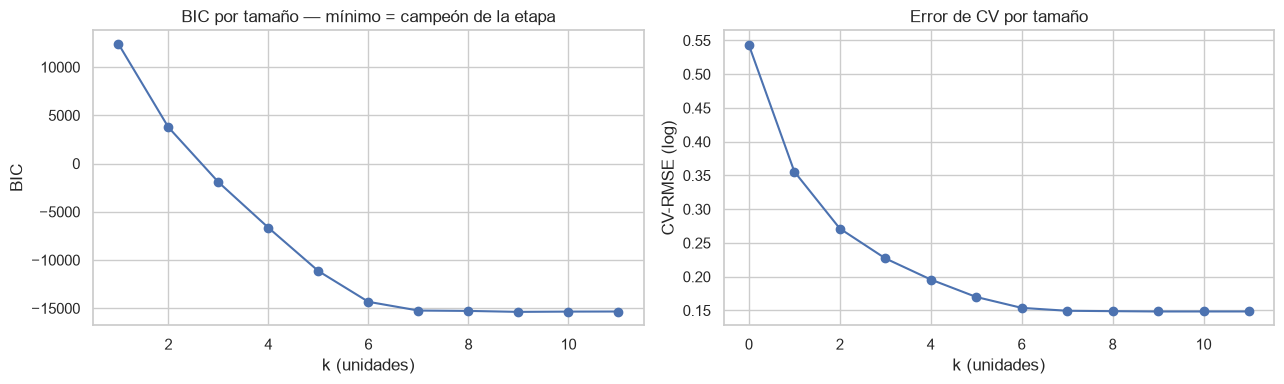

In [8]:
# Universo según la variante ganadora (regla Q6a)
if VARIANTE_GANADORA == "agrupado":
    UNIDADES = GRUPOS
    universo_nota = "los 11 grupos completos"
else:
    union_libre = sorted({c for n in CONFIG_STEPWISE
                          for c in selecciones[("libre", n)]["columnas"]})
    if len(union_libre) > 20:
        universo_cols = selecciones[("libre", "BIC")]["columnas"]
        universo_nota = (f"unión libre de {len(union_libre)} columnas inviable: "
                         "universo reducido al conjunto BIC (recorte declarado)")
    else:
        universo_cols = union_libre
        universo_nota = f"unión de las corridas stepwise libre ({len(union_libre)} columnas)"
    UNIDADES = {c: [c] for c in universo_cols}
print(f"Best Subset sobre {universo_nota}: {len(UNIDADES)} unidades "
      f"→ 2^{len(UNIDADES)} = {2 ** len(UNIDADES):,} subconjuntos")

# Búsqueda exhaustiva por tamaño con la matriz de Gram (RSS exactos, sin refits)
import itertools
Xmat = np.column_stack([np.ones(len(train)),
                        train[FEATURES_BASE].astype(float).to_numpy()])
yv = train[Y].astype(float).to_numpy()
XtX, Xty, yty = Xmat.T @ Xmat, Xmat.T @ yv, float(yv @ yv)
pos = {c: i + 1 for i, c in enumerate(FEATURES_BASE)}
unidad_idx = {u: [pos[c] for c in cols] for u, cols in UNIDADES.items()}
nombres_unidades = list(UNIDADES.keys())

mejor_por_k = {}
for k in range(len(nombres_unidades) + 1):
    mejor = None
    for combo in itertools.combinations(nombres_unidades, k):
        idx = [0] + [i for u in combo for i in unidad_idx[u]]
        A = XtX[np.ix_(idx, idx)]
        try:
            beta = np.linalg.solve(A, Xty[idx])
        except np.linalg.LinAlgError:
            continue
        rss = yty - float(Xty[idx] @ beta)
        if mejor is None or rss < mejor[1]:
            mejor = (combo, rss)
    mejor_por_k[k] = mejor

filas_bs = []
modelos_bs = {}
for k, (combo, rss) in mejor_por_k.items():
    cols_k = [c for c in FEATURES_BASE if c in {x for u in combo for x in UNIDADES[u]}]
    if cols_k:
        m_k = fit_ols(cols_k)
        modelos_bs[k] = m_k
        cv_k, se_k = cv_rmse(cols_k)
        filas_bs.append({"k_unidades": k, "unidades": ", ".join(combo),
                         "n_columnas": len(cols_k), "RSS_log": float(m_k.ssr),
                         "R2": float(m_k.rsquared), "Adj_R2": float(m_k.rsquared_adj),
                         "AIC": float(m_k.aic), "BIC": float(m_k.bic),
                         "CV_RMSE_log": cv_k, "CV_SE": se_k})
    else:
        filas_bs.append({"k_unidades": 0, "unidades": "(solo intercepto)",
                         "n_columnas": 0, "RSS_log": rss, "R2": 0.0,
                         "Adj_R2": 0.0, "AIC": np.nan, "BIC": np.nan,
                         "CV_RMSE_log": cv_rmse([])[0], "CV_SE": cv_rmse([])[1]})
tabla_bs = pd.DataFrame(filas_bs)
display(tabla_bs.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(tabla_bs["k_unidades"], tabla_bs["BIC"], marker="o")
axes[0].set_xlabel("k (unidades)"); axes[0].set_ylabel("BIC")
axes[0].set_title("BIC por tamaño — mínimo = campeón de la etapa")
axes[1].errorbar(tabla_bs["k_unidades"], tabla_bs["CV_RMSE_log"],
                 yerr=tabla_bs["CV_SE"], marker="o", capsize=3)
axes[1].set_xlabel("k (unidades)"); axes[1].set_ylabel("CV-RMSE (log)")
axes[1].set_title("Error de CV por tamaño")
plt.tight_layout(); plt.show()


In [9]:
fila_campeon = tabla_bs.loc[tabla_bs["BIC"].idxmin()]
K_CAMPEON = int(fila_campeon["k_unidades"])
combo_campeon = tuple(u.strip() for u in fila_campeon["unidades"].split(",")) \
    if fila_campeon["unidades"] != "(solo intercepto)" else ()
COLS_BS = [c for c in FEATURES_BASE
           if c in {x for u in combo_campeon for x in UNIDADES[u]}]
modelo_bs = modelos_bs[K_CAMPEON]
print(f"Campeón Best Subset (mínimo BIC): k = {K_CAMPEON} unidades, "
      f"{len(COLS_BS)} columnas, BIC = {fila_campeon['BIC']:.1f}")
print("unidades:", combo_campeon)
print("columnas:", COLS_BS)

# Comparación greedy vs. exhaustivo al mismo tamaño (¿el stepwise acertó?)
cols_step_ganador = selecciones[(VARIANTE_GANADORA, "BIC")]["columnas"]
m_step_bic = modelos_stepwise[(VARIANTE_GANADORA, "BIC")]
print(f"\nStepwise {VARIANTE_GANADORA} BIC: {len(cols_step_ganador)} columnas, "
      f"BIC = {m_step_bic.bic:.1f}, RSS = {m_step_bic.ssr:.3f}")
print(f"Best Subset k={K_CAMPEON}:        {len(COLS_BS)} columnas, "
      f"BIC = {modelo_bs.bic:.1f}, RSS = {modelo_bs.ssr:.3f}")
print(f"¿Mismo conjunto de columnas? {set(cols_step_ganador) == set(COLS_BS)}")
k_min_cv = int(tabla_bs.loc[tabla_bs['CV_RMSE_log'].idxmin(), 'k_unidades'])
print(f"k de mínimo CV: {k_min_cv} | k de mínimo BIC: {K_CAMPEON} "
      "(si difieren, queda documentado; el campeón de la etapa es el de BIC)")


Campeón Best Subset (mínimo BIC): k = 9 unidades, 34 columnas, BIC = -15373.7
unidades: ('log_area_z', 'log_center_z', 'log_metro_z', 'furnished', 'pets_allowed', 'building_type', 'renovation', 'okrug', 'metro_line')
columnas: ['log_area_z', 'log_center_z', 'log_metro_z', 'furnished', 'pets_allowed', 'building_type_brick', 'building_type_khrushchev', 'building_type_modern_panel', 'building_type_monolith', 'building_type_stalin', 'renovation_designer', 'renovation_euro', 'renovation_no_renovation', 'okrug_CAO', 'okrug_NAO', 'okrug_SAO', 'okrug_SZAO', 'okrug_TAO', 'okrug_VAO', 'okrug_YuAO', 'okrug_YuZAO', 'okrug_ZAO', 'okrug_ZelAO', 'metro_line_Arbatsko-Pokrovskaya', 'metro_line_Bolshaya Koltsevaya', 'metro_line_Filyovskaya', 'metro_line_Kalininskaya', 'metro_line_Koltsevaya', 'metro_line_Lyublinsko-Dmitrovskaya', 'metro_line_MCC', 'metro_line_Serpukhovsko-Timiryazevskaya', 'metro_line_Sokolnicheskaya', 'metro_line_Tagansko-Krasnopresnenskaya', 'metro_line_Zamoskvoretskaya']

Stepwise ag

**Lectura de Best Subset.** El mínimo BIC cae en k = 9 grupos (34 columnas),
exactamente el mismo conjunto al que llegaron las tres corridas stepwise
agrupadas: `log_area_z`, `log_center_z`, `log_metro_z`, `furnished`,
`pets_allowed`, `building_type`, `renovation`, `okrug` y `metro_line`. La
búsqueda exhaustiva **valida al greedy**: en 2.048 subconjuntos no existe uno
mejor de su tamaño ni de ningún otro según BIC. Agregar el décimo grupo
(`rooms`, k = 10) o el undécimo (`deposit_months`, k = 11, el baseline) baja el
RSS en menos de 0,03 a costa de 3–4 parámetros: el BIC los castiga y sube. La
curva de CV es plana desde k = 8, coherente con que el margen entre modelos
grandes es ruido de estimación y no señal.

## 4. Elección del modelo final: el punto medio del bias–variance

«Punto medio» no es el promedio entre el modelo más simple y el más complejo:
es el punto donde agregar complejidad ya no baja el error de predicción de
forma apreciable. A la izquierda manda el sesgo; a la derecha, la varianza.

**Regla declarada antes:** candidatos = baseline (38), los tres stepwise de la
variante ganadora y el campeón Best Subset. Con el CV 5-fold de siempre
(mismos folds, RMSE en log), gana el candidato con **menos columnas** entre
los que estén dentro de **1 error estándar del mejor CV-RMSE**; desempate por
menor BIC. Si dos caminos llegaron al mismo conjunto de columnas, el final es
ese conjunto (con todos sus nombres registrados). Al elegido se le corre la
batería completa y recién entonces se evalúa test, una sola vez.

In [10]:
candidatos = {"baseline": FEATURES_BASE}
for nombre in CONFIG_STEPWISE:
    candidatos[f"stepwise_{VARIANTE_GANADORA}_{nombre}"] = \
        selecciones[(VARIANTE_GANADORA, nombre)]["columnas"]
candidatos["best_subset"] = COLS_BS

modelos_cand = {}
filas_cand = []
for nombre_c, cols_c in candidatos.items():
    m_c = fit_ols(cols_c)
    modelos_cand[nombre_c] = m_c
    met_c = metricas_log(m_c, cols_c)
    filas_cand.append({"candidato": nombre_c, **met_c})
tabla_cand = pd.DataFrame(filas_cand)

mejor_cv = tabla_cand["CV_RMSE_log"].min()
se_mejor = float(tabla_cand.loc[tabla_cand["CV_RMSE_log"].idxmin(), "CV_SE"])
tabla_cand["dentro_1SE"] = tabla_cand["CV_RMSE_log"] <= mejor_cv + se_mejor
elegibles = tabla_cand[tabla_cand["dentro_1SE"]].sort_values(
    ["n_columnas", "BIC"], ascending=[True, True])
fila_final = elegibles.iloc[0]
FINAL_COLS = candidatos[fila_final["candidato"]]
FINAL_ALIAS = [n for n, c in candidatos.items() if set(c) == set(FINAL_COLS)]
modelo_final = fit_ols(FINAL_COLS)
display(tabla_cand[["candidato", "n_columnas", "R2", "Adj_R2", "AIC", "BIC",
                    "MAE_log", "CV_RMSE_log", "CV_SE", "dentro_1SE"]].round(5))
print(f"\nMejor CV-RMSE: {mejor_cv:.5f} (SE = {se_mejor:.5f}) → umbral 1 SE: {mejor_cv + se_mejor:.5f}")
print(f"FINAL: {len(FINAL_COLS)} columnas — alcanzado por: {FINAL_ALIAS}")
print("columnas:", FINAL_COLS)
print(modelo_final.summary().as_text())


,candidato,n_columnas,R2,Adj_R2,AIC,BIC,MAE_log,CV_RMSE_log,CV_SE,dentro_1SE
0,baseline,38,0.92568,0.92550,-15635.3067,-15335.77329,0.11872,0.14850,0.00057,True
1,stepwise_agrupado_AIC,34,0.92567,0.92552,-15642.4820,-15373.66996,0.11874,0.14846,0.00057,True
2,stepwise_agrupado_BIC,34,0.92567,0.92552,-15642.4820,-15373.66996,0.11874,0.14846,0.00057,True
3,stepwise_agrupado_AdjR2,34,0.92567,0.92552,-15642.4820,-15373.66996,0.11874,0.14846,0.00057,True
4,best_subset,34,0.92567,0.92552,-15642.4820,-15373.66996,0.11874,0.14846,0.00057,True



Mejor CV-RMSE: 0.14846 (SE = 0.00057) → umbral 1 SE: 0.14904
FINAL: 34 columnas — alcanzado por: ['stepwise_agrupado_AIC', 'stepwise_agrupado_BIC', 'stepwise_agrupado_AdjR2', 'best_subset']
columnas: ['log_area_z', 'log_center_z', 'log_metro_z', 'furnished', 'pets_allowed', 'building_type_brick', 'building_type_khrushchev', 'building_type_modern_panel', 'building_type_monolith', 'building_type_stalin', 'renovation_designer', 'renovation_euro', 'renovation_no_renovation', 'okrug_CAO', 'okrug_NAO', 'okrug_SAO', 'okrug_SZAO', 'okrug_TAO', 'okrug_VAO', 'okrug_YuAO', 'okrug_YuZAO', 'okrug_ZAO', 'okrug_ZelAO', 'metro_line_Arbatsko-Pokrovskaya', 'metro_line_Bolshaya Koltsevaya', 'metro_line_Filyovskaya', 'metro_line_Kalininskaya', 'metro_line_Koltsevaya', 'metro_line_Lyublinsko-Dmitrovskaya', 'metro_line_MCC', 'metro_line_Serpukhovsko-Timiryazevskaya', 'metro_line_Sokolnicheskaya', 'metro_line_Tagansko-Krasnopresnenskaya', 'metro_line_Zamoskvoretskaya']
                            OLS Regres

===== Modelo final =====
— Paso 1 · Ajuste global —
R2                    0.9257
Adj_R2                0.9255
F_statistic        5848.0138
Prob(F)               0.0000
Log-Likelihood     7856.2410
AIC              -15642.4820
BIC              -15373.6700
n                 16000.0000
Df_modelo            34.0000
Df_residuos       15965.0000
Cond_No              19.4614

— Paso 2 · Colinealidad (VIF alto ⇒ coef. poco creíble; Tol = 1/VIF) —


,VIF,Tol
log_center_z,4.432,0.226
okrug_TAO,2.886,0.347
okrug_CAO,2.314,0.432
okrug_NAO,1.942,0.515
okrug_VAO,1.927,0.519
log_metro_z,1.922,0.520
okrug_YuAO,1.822,0.549
metro_line_Arbatsko-Pokrovskaya,1.806,0.554
metro_line_Serpukhovsko-Timiryazevskaya,1.802,0.555
okrug_SAO,1.798,0.556


VIF máximo: 4.43 (umbral de alerta habitual: 5; severo: 10)

— Paso 3 · Coeficientes (t ≠ 0 y p ≤ 0,05) —


,coef,std_err,t,p_valor,IC95_inf,IC95_sup,significativo_005
const,10.4606,0.0052,2006.1623,0.0000,10.4504,10.4708,True
log_area_z,0.2274,0.0012,193.9142,0.0000,0.2251,0.2297,True
log_center_z,-0.1480,0.0025,-59.9817,0.0000,-0.1528,-0.1432,True
log_metro_z,-0.1555,0.0016,-95.6855,0.0000,-0.1587,-0.1523,True
furnished,0.0790,0.0026,30.8828,0.0000,0.0740,0.0841,True
pets_allowed,-0.0266,0.0026,-10.4433,0.0000,-0.0316,-0.0216,True
building_type_brick,0.1282,0.0036,35.3594,0.0000,0.1211,0.1353,True
building_type_khrushchev,-0.0772,0.0038,-20.2340,0.0000,-0.0847,-0.0697,True
building_type_modern_panel,0.0821,0.0037,22.2348,0.0000,0.0749,0.0893,True
building_type_monolith,0.1794,0.0035,50.6846,0.0000,0.1725,0.1863,True


no significativos (p > 0,05): ['metro_line_Bolshaya Koltsevaya', 'metro_line_Kalininskaya', 'metro_line_Lyublinsko-Dmitrovskaya', 'metro_line_MCC', 'metro_line_Serpukhovsko-Timiryazevskaya']

— Paso 5 · Normalidad (respaldo numérico; manda la lectura visual) —
Omnibus          20.0867
Prob(Omnibus)     0.0000
Skew             -0.0727
Kurtosis          2.9085
Jarque-Bera      19.6936
Prob(JB)          0.0001

— Paso 6 · Independencia —
Durbin-Watson: 1.990  (≈2 sin autocorr.; en corte transversal depende del orden de filas: se reporta con cautela)

— Paso 7 · Costo en log (escala del ajuste, train) —
RSS             350.87738
MSE (=RSS/n)      0.02193
MAE               0.11874


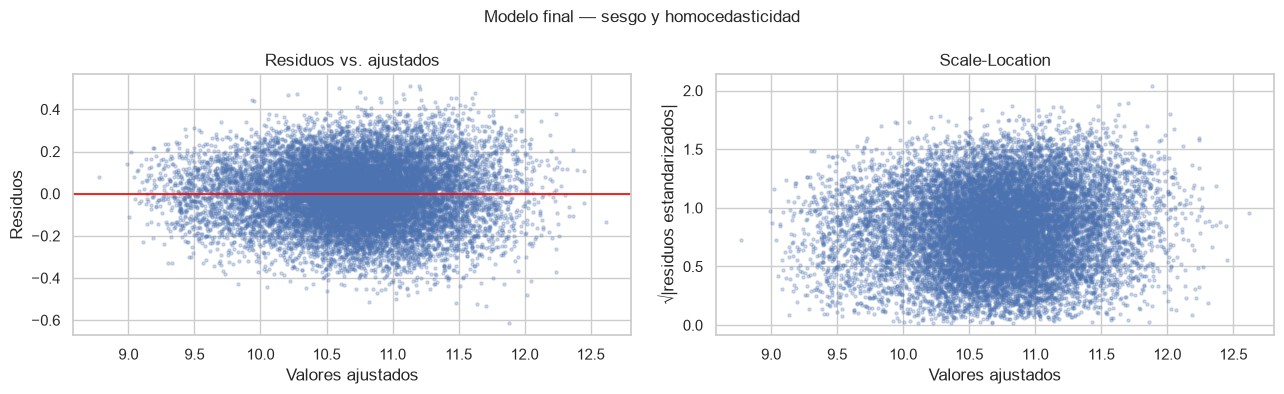

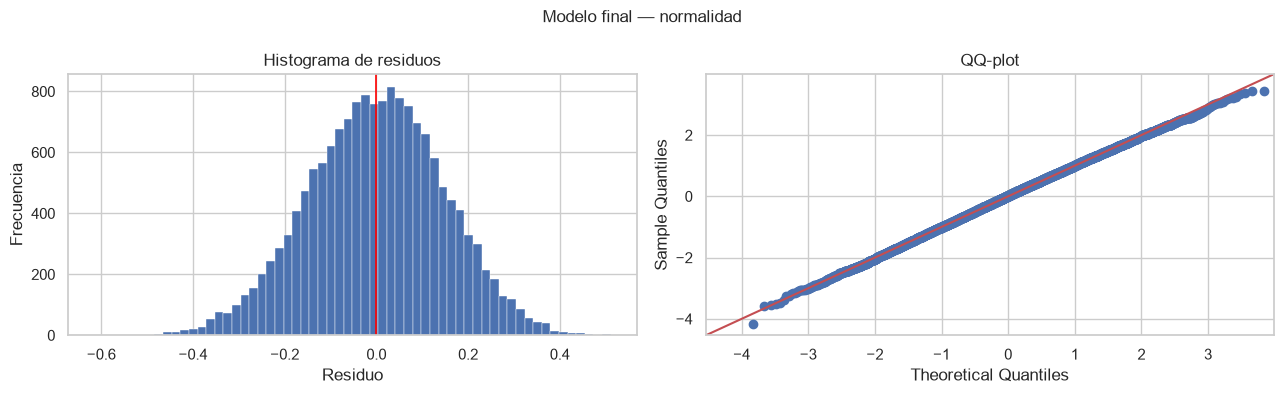

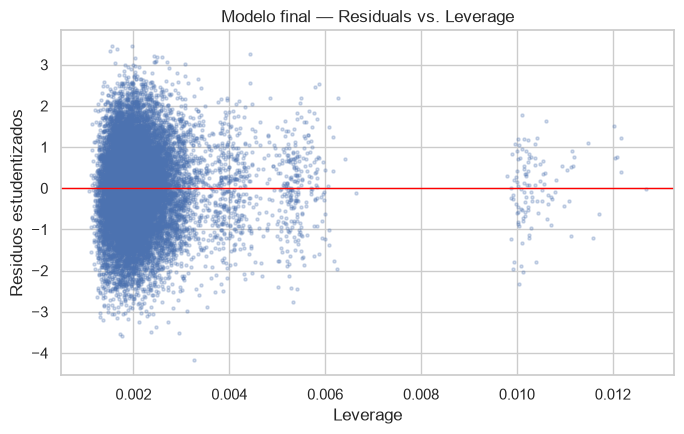

Distancia de Cook máxima: 0.0016 (muy por debajo de 1: ningún punto domina el ajuste)


In [11]:
res_final = bateria_tablas(modelo_final, FINAL_COLS, "Modelo final")
graf_final = graficos_diagnostico(modelo_final, "Modelo final")


**Lectura del modelo final.** Es el conjunto de 34 columnas (9 grupos) al que
llegaron, por caminos distintos, las tres corridas stepwise agrupadas y la
búsqueda exhaustiva: quedan afuera `deposit_months` y el bloque `rooms`, que no
pagaban su parámetro en ninguna comparación. Su batería replica la del
baseline casi número por número —mismo VIF máximo (4,43), residuos centrados
y simétricos, QQ sobre la recta, Durbin-Watson ≈ 1,99, Cook máximo 0,0016—,
que es exactamente lo que la regla de 1 SE promete: la misma calidad de
ajuste y de supuestos que el modelo completo, con 4 columnas y 2
características menos, y con cada bloque categórico íntegro e interpretable.

## 5. Evaluación en test (única, sobre el modelo final ya elegido)

Recién ahora se abre test. En log se reporta el desempeño en la escala del
ajuste; en RUB, las predicciones `expm1(...)` contra `monthly_rent_rub`, con el
**MAE en RUB como error principal comunicable**. Si estos números salieran
mal, se reportarían igual: volver atrás a elegir otro modelo con test a la
vista filtraría información y el error dejaría de ser honesto.

In [12]:
def evaluar_test(modelo, cols):
    filas = []
    for datos, nombre_d in [(train, "train"), (test, "test")]:
        X = sm.add_constant(datos[list(cols)].astype(float), has_constant="add")
        pred_log = modelo.predict(X)
        pred_rub = np.expm1(pred_log)
        filas.append({
            "conjunto": nombre_d,
            "MAE_log": mean_absolute_error(datos[Y], pred_log),
            "RMSE_log": float(np.sqrt(mean_squared_error(datos[Y], pred_log))),
            "R2_log": r2_score(datos[Y], pred_log),
            "MAE_RUB": mean_absolute_error(datos[TARGET], pred_rub),
            "RMSE_RUB": float(np.sqrt(mean_squared_error(datos[TARGET], pred_rub))),
            "R2_RUB": r2_score(datos[TARGET], pred_rub),
        })
    return pd.DataFrame(filas)


tabla_test = evaluar_test(modelo_final, FINAL_COLS)
display(tabla_test.round(5))
mae_test_rub = float(tabla_test.loc[tabla_test["conjunto"] == "test", "MAE_RUB"].iloc[0])
print(f"\nError principal del modelo final: MAE en test = {mae_test_rub:,.0f} RUB/mes")


,conjunto,MAE_log,RMSE_log,R2_log,MAE_RUB,RMSE_RUB,R2_RUB
0,train,0.11874,0.14809,0.92567,6429.40441,9523.80557,0.89899
1,test,0.11857,0.14829,0.92491,6457.90687,9706.03652,0.89634



Error principal del modelo final: MAE en test = 6,458 RUB/mes


**Lectura de test.** El error principal es un MAE de ≈ 6.458 RUB/mes en test
(R² en RUB ≈ 0,896; en log, R² ≈ 0,925), prácticamente idéntico al de train:
no hay brecha de sobreajuste apreciable, coherente con haber elegido por CV
el modelo más simple dentro del empate estadístico. Es, en la práctica, el
mismo error que daría el baseline de 38, obtenido con un modelo más chico y
defendible variable por variable.

## 6. Registro en MLflow (DagsHub remoto, experimento `Alquiler`)

Se verifica el `.env` (ignorado por Git, sin mostrar el token), se
inicializa DagsHub para `matiasgastonlonghino/MOSCOW_IDA` y se
registra **un run por modelo candidato del proceso**: baseline, los 6 stepwise
(2 variantes × 3 criterios) y el campeón Best Subset — 8 runs. Cada run lleva
parámetros del método, métricas en train en ambas escalas de nombre
(`..._log` / `..._rub` cuando aplica), el `summary()` y los coeficientes como
artefactos, y el modelo `statsmodels` registrado. Solo el run canónico del
modelo final (el de Best Subset, por ser el mismo conjunto alcanzado en la
última etapa) incluye además las métricas de test ya calculadas arriba y la
marca `modelo_final`; los demás runs no tocan test. Al final, cada run se
verifica contra el servidor remoto.

In [13]:
# Configuración MLflow / DagsHub
import os
from importlib.metadata import version

assert Path(sys.prefix).resolve() == (RAIZ / ".venv").resolve()
archivo_env = RAIZ / ".env"
import subprocess
assert subprocess.run(["git", "check-ignore", "-q", ".env"], cwd=RAIZ,
                      capture_output=True).returncode == 0, ".env debe estar ignorado por Git"
assert subprocess.run(["git", "ls-files", "--error-unmatch", ".env"], cwd=RAIZ,
                      capture_output=True).returncode != 0, ".env no debe estar versionado"
from dotenv import load_dotenv
load_dotenv(dotenv_path=archivo_env, override=True)
assert os.environ.get("DAGSHUB_USER_TOKEN", "").strip(), "Falta DAGSHUB_USER_TOKEN en .env"
print("Credencial cargada desde .env (ignorado y no versionado).")

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import dagshub
import mlflow
import mlflow.statsmodels
from dagshub.common.api import RepoAPI
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

tracking_uri_dagshub = "https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow"
assert mlflow.active_run() is None
RepoAPI("matiasgastonlonghino/MOSCOW_IDA", host="https://dagshub.com").get_repo_info()
dagshub.init(repo_owner="matiasgastonlonghino", repo_name="MOSCOW_IDA",
             mlflow=True, dvc=False, patch_mlflow=False)
mlflow.set_tracking_uri(tracking_uri_dagshub)
assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
experimento = mlflow.set_experiment("Alquiler")
print(f"tracking: {tracking_uri_dagshub} | experimento: {experimento.name} "
      f"(id {experimento.experiment_id})")
VERSIONES = {n: version(n) for n in
             ["statsmodels", "numpy", "pandas", "scipy", "scikit-learn", "mlflow", "dagshub"]}
print("versiones:", VERSIONES)


Credencial cargada desde .env (ignorado y no versionado).


/Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accessing as MontillaTomas

Initialized MLflow to track repo "matiasgastonlonghino/MOSCOW_IDA"

Repository matiasgastonlonghino/MOSCOW_IDA initialized!

tracking: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow | experimento: Alquiler (id 2)
versiones: {'statsmodels': '0.15.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'mlflow': '3.16.1', 'dagshub': '0.7.3'}


In [14]:
def tabla_coef_mlflow(modelo):
    return pd.DataFrame({
        "variable": modelo.params.index, "coeficiente": modelo.params.to_numpy(),
        "std_err": modelo.bse.to_numpy(), "t_value": modelo.tvalues.to_numpy(),
        "p_value": modelo.pvalues.to_numpy(),
        "significativo_005": modelo.pvalues.to_numpy() < 0.05})


def registrar_run(nombre_run, metodo, criterio, cols, modelo, extra_textos, extra_json,
                  metricas_extra=None):
    assert mlflow.active_run() is None
    diseno = sm.add_constant(train[list(cols)].astype(float), has_constant="add")
    met = metricas_log(modelo, cols)
    metricas = {
        "r2_log_train": met["R2"], "r2_adj_log_train": met["Adj_R2"],
        "mae_log_train": met["MAE_log"], "mse_log_train": met["MSE_log"],
        "rss_log_train": met["RSS_log"], "cv_rmse_log_train": met["CV_RMSE_log"],
        "aic": met["AIC"], "bic": met["BIC"],
    }
    if metricas_extra:
        metricas.update(metricas_extra)
    parametros = {
        "nombre_modelo": nombre_run, "tipo_modelo": "statsmodels.OLS",
        "metodo_seleccion": metodo, "criterio": criterio, "target": Y,
        "n_predictoras": len(cols), "n_train": len(train), "n_test": len(test),
        "division": "80/20 de 02 (sin re-dividir)", "intercepto": True,
        "experimento": "Alquiler",
    }
    with mlflow.start_run(experiment_id=experimento.experiment_id,
                          run_name=nombre_run) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})
        mlflow.log_text(modelo.summary().as_text(), "resumen_ols.txt")
        mlflow.log_text(tabla_coef_mlflow(modelo).to_csv(index=False), "coeficientes.csv")
        for ruta, texto in extra_textos.items():
            mlflow.log_text(texto, ruta)
        for ruta, obj in extra_json.items():
            mlflow.log_dict(obj, ruta)
        info = mlflow.statsmodels.log_model(
            modelo, name="modelo",
            signature=infer_signature(diseno.head(5), modelo.predict(diseno.head(5))),
            pip_requirements=[f"{p}=={VERSIONES[p]}" for p in
                              ["statsmodels", "numpy", "pandas", "scipy", "mlflow"]])
        mlflow.log_dict({"model_uri": info.model_uri}, "modelo_uri.json")
        return {"run_id": run.info.run_id, "model_uri": info.model_uri,
                "metricas": metricas, "parametros": parametros}


# Los 8 modelos del proceso
runs_a_registrar = []
runs_a_registrar.append({
    "nombre": "OLS_Completo_Baseline", "metodo": "baseline_completo",
    "criterio": "ninguno", "cols": FEATURES_BASE, "modelo": baseline,
    "textos": {}, "json": {"variables_predictoras.json": {"predictoras": FEATURES_BASE}}})
for (variante, nombre), s in selecciones.items():
    runs_a_registrar.append({
        "nombre": f"OLS_Forward_{variante.capitalize()}_{nombre}",
        "metodo": f"forward_stepwise_{variante}", "criterio": CONFIG_STEPWISE[nombre]["criterio"],
        "cols": s["columnas"], "modelo": modelos_stepwise[(variante, nombre)],
        "textos": {"historial_forward.csv": s["historial"].to_csv(index=False)},
        "json": {"seleccion.json": {"seleccionadas": s["seleccionadas"],
                                    "columnas_predictoras": s["columnas"]}}})
metricas_final_test = {
    "mae_log_test": float(tabla_test.loc[tabla_test["conjunto"] == "test", "MAE_log"].iloc[0]),
    "r2_log_test": float(tabla_test.loc[tabla_test["conjunto"] == "test", "R2_log"].iloc[0]),
    "mae_rub_test": mae_test_rub,
    "rmse_rub_test": float(tabla_test.loc[tabla_test["conjunto"] == "test", "RMSE_RUB"].iloc[0]),
    "r2_rub_test": float(tabla_test.loc[tabla_test["conjunto"] == "test", "R2_RUB"].iloc[0]),
}
es_final_bs = set(COLS_BS) == set(FINAL_COLS)
runs_a_registrar.append({
    "nombre": "OLS_BestSubset_BIC", "metodo": "best_subset", "criterio": "bic",
    "cols": COLS_BS, "modelo": modelo_bs,
    "textos": {"tabla_best_subset.csv": tabla_bs.to_csv(index=False)},
    "json": {"seleccion.json": {"unidades": list(combo_campeon),
                                "columnas_predictoras": COLS_BS}},
    "metricas_extra": metricas_final_test if es_final_bs else None})
assert len(runs_a_registrar) == 8
print([r["nombre"] for r in runs_a_registrar])


['OLS_Completo_Baseline', 'OLS_Forward_Agrupado_AIC', 'OLS_Forward_Agrupado_BIC', 'OLS_Forward_Agrupado_AdjR2', 'OLS_Forward_Libre_AIC', 'OLS_Forward_Libre_BIC', 'OLS_Forward_Libre_AdjR2', 'OLS_BestSubset_BIC']


In [15]:
registros = {}
for spec in runs_a_registrar:
    reg = registrar_run(spec["nombre"], spec["metodo"], spec["criterio"],
                        spec["cols"], spec["modelo"], spec["textos"], spec["json"],
                        metricas_extra=spec.get("metricas_extra"))
    registros[spec["nombre"]] = reg
    print(f"{spec['nombre']}: FINISHED {reg['run_id']}")

# Marca del modelo final sobre su run canónico (Best Subset, última etapa)
cliente = MlflowClient(tracking_uri=tracking_uri_dagshub)
if es_final_bs:
    cliente.set_tag(registros["OLS_BestSubset_BIC"]["run_id"], "modelo_final", "true")
    cliente.set_tag(registros["OLS_BestSubset_BIC"]["run_id"], "mae_rub_test",
                    f"{mae_test_rub:.0f}")
print("run canónico del final: OLS_BestSubset_BIC (mismo conjunto que el elegido por 1 SE)"
      if es_final_bs else "el conjunto Best Subset no coincide con el final; ver candidatos")
assert mlflow.active_run() is None


🏃 View run OLS_Completo_Baseline at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/173b862ef850475bbe07c3463485cc59
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Completo_Baseline: FINISHED 173b862ef850475bbe07c3463485cc59


🏃 View run OLS_Forward_Agrupado_AIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/6f9e3090bb4c4abc8a373830f1fa024e
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Forward_Agrupado_AIC: FINISHED 6f9e3090bb4c4abc8a373830f1fa024e


🏃 View run OLS_Forward_Agrupado_BIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/678904ead8ca49e28cea8ce924aca2ab
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


...

🏃 View run OLS_Forward_Libre_AdjR2 at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/7d4d6a9a65c347a6bc58ba8618aa3882
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Forward_Libre_AdjR2: FINISHED 7d4d6a9a65c347a6bc58ba8618aa3882


🏃 View run OLS_BestSubset_BIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/a5ed160996a74044b36daec6fd9a161b
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_BestSubset_BIC: FINISHED a5ed160996a74044b36daec6fd9a161b


run canónico del final: OLS_BestSubset_BIC (mismo conjunto que el elegido por 1 SE)


In [16]:
# Verificación remota de los 8 runs
import math
verificacion = []
for nombre_run, reg in registros.items():
    remoto = cliente.get_run(reg["run_id"])
    assert remoto.info.status == "FINISHED", nombre_run
    assert remoto.data.tags["mlflow.runName"] == nombre_run, nombre_run
    for k, v in reg["parametros"].items():
        assert remoto.data.params[k] == str(v), (nombre_run, k)
    for k, v in reg["metricas"].items():
        assert math.isclose(remoto.data.metrics[k], float(v),
                            rel_tol=1e-9, abs_tol=1e-12), (nombre_run, k)
    rutas = {a.path for a in cliente.list_artifacts(reg["run_id"])}
    assert {"resumen_ols.txt", "coeficientes.csv", "modelo_uri.json"} <= rutas, nombre_run
    verificacion.append({"run": nombre_run, "run_id": reg["run_id"][:8] + "...",
                         "estado": remoto.info.status,
                         "n_artefactos": len(rutas)})
# Recuperación del modelo final desde el servidor y chequeo de predicción
recuperado = mlflow.statsmodels.load_model(registros["OLS_BestSubset_BIC"]["model_uri"])
diseno_final = sm.add_constant(train[FINAL_COLS].astype(float), has_constant="add")
np.testing.assert_allclose(recuperado.predict(diseno_final.head(20)),
                           modelo_final.predict(diseno_final.head(20)),
                           rtol=1e-8, atol=1e-6)
display(pd.DataFrame(verificacion))
print(f"8 runs verificados en el experimento 'Alquiler': "
      f"{tracking_uri_dagshub}/#/experiments/{experimento.experiment_id}")
print(f"Modelo final recuperado del servidor y predicciones idénticas (20 filas).")


,run,run_id,estado,n_artefactos
0,OLS_Completo_Baseline,173b862e...,FINISHED,4
1,OLS_Forward_Agrupado_AIC,6f9e3090...,FINISHED,5
2,OLS_Forward_Agrupado_BIC,678904ea...,FINISHED,5
3,OLS_Forward_Agrupado_AdjR2,6c38c628...,FINISHED,5
4,OLS_Forward_Libre_AIC,9048b421...,FINISHED,5
5,OLS_Forward_Libre_BIC,e4008917...,FINISHED,5
6,OLS_Forward_Libre_AdjR2,7d4d6a9a...,FINISHED,5
7,OLS_BestSubset_BIC,a5ed1609...,FINISHED,5


8 runs verificados en el experimento 'Alquiler': https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2
Modelo final recuperado del servidor y predicciones idénticas (20 filas).


## Cierre — qué modelo queda y con qué error

- **Modelo final:** OLS de `statsmodels` sobre `log_rent` con **34 columnas /
  9 características** (`log_area_z`, `log_center_z`, `log_metro_z`, `furnished`,
  `pets_allowed` y los bloques `building_type`, `renovation`, `okrug`,
  `metro_line`), al que llegaron por caminos independientes las tres corridas
  Forward Stepwise agrupadas y la búsqueda exhaustiva Best Subset, y que la
  regla de 1 SE eligió entre los 5 candidatos por ser el más simple dentro del
  empate estadístico de CV. Quedan afuera `deposit_months` y el bloque `rooms`.
- **Por qué este y no otro:** el baseline de 38 predice lo mismo (ΔCV ≈ 0,0000)
  con más parámetros; la variante libre logra mejor BIC podando líneas de
  metro sueltas, pero sin ventaja de CV que justifique fragmentar categorías
  ni sus 38 decisiones de selección (regla de la competencia, declarada antes
  de correrla). Cada descarte tiene su comparación y su criterio en las
  secciones 2 a 4.
- **Error comunicable:** MAE en test ≈ **6.458 RUB/mes** (única evaluación en
  test, doble escala en la sección 5), con la batería completa de supuestos
  verificada sobre el final en la sección 4.
- **Trazabilidad:** los 8 modelos del proceso están en MLflow, experimento
  `Alquiler` de DagsHub, con el final marcado (`modelo_final`) sobre el run
  `OLS_BestSubset_BIC`, verificados contra el servidor en la sección 6.
- **Fuera de alcance:** variables fuera de las 38 (incluidas
  las dummies de `district`/`metro_station`), modelos no-OLS y cualquier
  corrección automática a partir del diagnóstico.